# Homework 4

In this homework, we will use the 2026 lead-scoring data.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as  plt

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [3]:
!wget $data -O homework-data-week-4.csv

--2026-10-13 03:18:14--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘homework-data-week-4.csv’

homework-data-week- 100%[===================>] 272.21K  --.-KB/s    in 0.003s  

2026-10-13 03:18:14 (87.3 MB/s) - ‘homework-data-week-4.csv’ saved [278746/278746]



In [4]:
df = pd.read_csv('homework-data-week-4.csv')
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In this dataset our desired target for classification task will be `converted` variable -- has the client signed up to the platform or not.

### Data preparation
- Check if the missing values are presented in the features.
- If there are missing values:
  - For categorical features, replace them with 'NA'
  - For numerical features, replace with with 0.0


In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
categorical =['lead_source', 'industry', 'employment_status', 'location']

In [7]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']

In [8]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
df[categorical]

,lead_source,industry,employment_status,location
0,organic_search,technology,employed,europe
1,social_media,technology,employed,south_america
2,referral,retail,employed,europe
3,paid_ads,manufacturing,student,NaN
4,referral,manufacturing,student,north_america
...,...,...,...,...
4995,organic_search,education,employed,asia
4996,NaN,technology,employed,north_america
4997,organic_search,finance,employed,asia
4998,referral,technology,employed,africa


In [10]:
df[categorical].isnull().sum()

lead_source          148
industry             240
employment_status    194
location             208
dtype: int64

In [11]:
df[categorical] = df[categorical].fillna('NA')

In [12]:
df[categorical]

,lead_source,industry,employment_status,location
0,organic_search,technology,employed,europe
1,social_media,technology,employed,south_america
2,referral,retail,employed,europe
3,paid_ads,manufacturing,student,NA
4,referral,manufacturing,student,north_america
...,...,...,...,...
4995,organic_search,education,employed,asia
4996,NA,technology,employed,north_america
4997,organic_search,finance,employed,asia
4998,referral,technology,employed,africa


In [13]:
df[numerical] = df[numerical].fillna(0)

In [14]:
df[numerical]

,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,88160.0,3,4,0.64
1,72688.0,3,7,0.72
2,44697.0,3,4,0.58
3,0.0,3,6,0.57
4,24062.0,4,5,0.62
...,...,...,...,...
4995,45834.0,2,2,0.37
4996,84831.0,2,5,0.51
4997,53636.0,4,6,0.75
4998,69430.0,4,8,0.79


## Setting up the validation framework
- Perform the train/validation/test split with Scikit-Learn.

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

In [17]:
len(df_full_train), len(df_test)

(4000, 1000)

In [18]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [19]:
len(df_train), len(df_val)

(3000, 1000)

Next, we format the index of the tables.

In [20]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Next, we get our target variables. The code below takes the column with the target variable, `converted`, and saves it outside the dataframe.

In [21]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

## Q1. ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

- For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
- Use the training dataset for that

In [22]:
from sklearn.metrics import roc_auc_score

for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    print(c, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


## Q2. 
Apply one-hot-encoding using `DictVectorizer` and train the logistic regression

In [23]:
from sklearn.feature_extraction import DictVectorizer

In [24]:
dv = DictVectorizer(sparse = False)

In [25]:
train_dicts = df_train[categorical + numerical].to_dict(orient= 'records')

In [26]:
train_dicts[0] #Shows the first entry of the dictionary

{'lead_source': 'paid_ads',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80198.0,
 'number_of_courses_viewed': 5,
 'interaction_count': 9,
 'lead_score': 0.91}

In [27]:
#Next, we fit our dict vectorizer

dv.fit(train_dicts)

DictVectorizer(sparse=False)

In [28]:
X_train = dv.transform(train_dicts)

In [29]:
val_dicts = df_val[categorical + numerical].to_dict(orient= 'records')

In [30]:
#We don't fit on the validation dataset, we just transform

X_val = dv.transform(val_dicts)

Now, we are ready to train our model.

In [31]:
from sklearn.linear_model import LogisticRegression

In [32]:
#we train the model by calling the fit method
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [33]:
model.predict(X_train)

array([1, 1, 0, ..., 0, 1, 1], shape=(3000,))

In [34]:
model.predict_proba(X_train)

array([[0.1423449 , 0.8576551 ],
       [0.32109752, 0.67890248],
       [0.53998362, 0.46001638],
       ...,
       [0.55249255, 0.44750745],
       [0.25686501, 0.74313499],
       [0.10333236, 0.89666764]], shape=(3000, 2))

In [35]:
y_pred = model.predict_proba(X_val)[: ,1]
y_pred

array([0.54472295, 0.79005191, 0.50977882, 0.52913934, 0.82072017,
       0.54245972, 0.50178712, 0.54698383, 0.82553291, 0.40583727,
       0.91301561, 0.33581811, 0.3078986 , 0.42704772, 0.62192275,
       0.53665458, 0.41931913, 0.84087339, 0.79969125, 0.61790114,
       0.61625177, 0.68059912, 0.85605897, 0.80784865, 0.62045997,
       0.45970701, 0.54556694, 0.41221371, 0.72714005, 0.46812072,
       0.77222173, 0.79043872, 0.61433884, 0.78549743, 0.49753403,
       0.66077266, 0.69804748, 0.7689654 , 0.65657485, 0.64127885,
       0.66509096, 0.57942799, 0.67830929, 0.61186087, 0.86890227,
       0.41469665, 0.84130122, 0.74229349, 0.68028533, 0.71891426,
       0.86417924, 0.64043347, 0.54246978, 0.70225148, 0.27894882,
       0.70826471, 0.62310687, 0.47781739, 0.37914002, 0.69936026,
       0.52032849, 0.69977687, 0.75148933, 0.58087478, 0.47001782,
       0.56863462, 0.91297177, 0.79972016, 0.82206537, 0.36140182,
       0.66132377, 0.52330037, 0.79295454, 0.72068061, 0.71234

In [36]:
churn_decision = (y_pred >= 0.5)
churn_decision

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True, False, False, False,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
       False,  True, False,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True, False, False,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True, False,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False,  True,  True,  True, False,  True,
       False,  True,  True,  True,  True,  True,  True, False,  True,
       False,  True,

In [37]:
from sklearn.metrics import roc_auc_score

In [38]:
# Calculate AUC
auc = roc_auc_score(y_val, y_pred)

In [39]:
print(round(auc, 3))

0.732


### Q3 Precision and Recall
Now let's compute precision and recall for our model.

- Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
- For each threshold, compute precision and recall
- Plot them
  
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

First, we find the true positive, true negative, false positive and false negative.

In [40]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5

predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

tp = (predict_positive & actual_positive).sum() #We use the sum() to see how many are there.
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

Next, we evaluate not just one threshold, we look at it for all possible thresholds. 

In [41]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum() 
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

In [42]:
scores

[(np.float64(0.0), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.01), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.02), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.03), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.04), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.05), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.06), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.07), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.08), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.09), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.1), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.11), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 (np.float64(0.12), np.int64(586), np.int64(414), np.int64(0), np.int64(0)),
 

In [43]:
# Next, we turn it to a dataframe.
pd.DataFrame(scores)

,0,1,2,3,4
0,0.00,586,414,0,0
1,0.01,586,414,0,0
2,0.02,586,414,0,0
3,0.03,586,414,0,0
4,0.04,586,414,0,0
...,...,...,...,...,...
96,0.96,1,0,585,414
97,0.97,0,0,586,414
98,0.98,0,0,586,414
99,0.99,0,0,586,414


In [44]:
columns = ['thresholds', 'tp', 'fp', 'fn', 'tn']

df_scores = pd.DataFrame(scores, columns=columns)

In [45]:
df_scores

,thresholds,tp,fp,fn,tn
0,0.00,586,414,0,0
1,0.01,586,414,0,0
2,0.02,586,414,0,0
3,0.03,586,414,0,0
4,0.04,586,414,0,0
...,...,...,...,...,...
96,0.96,1,0,585,414
97,0.97,0,0,586,414
98,0.98,0,0,586,414
99,0.99,0,0,586,414


In [46]:
df_scores[::10]

,thresholds,tp,fp,fn,tn
0,0.0,586,414,0,0
10,0.1,586,414,0,0
20,0.2,586,414,0,0
30,0.3,586,403,0,11
40,0.4,573,362,13,52
50,0.5,531,294,55,120
60,0.6,457,190,129,224
70,0.7,311,82,275,332
80,0.8,139,23,447,391
90,0.9,19,1,567,413


In [47]:
df_scores['p'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['r'] = df_scores.tp / (df_scores.tp + df_scores.fn)

In [48]:
df_scores[::10]

,thresholds,tp,fp,fn,tn,p,r
0,0.0,586,414,0,0,0.586000,1.000000
10,0.1,586,414,0,0,0.586000,1.000000
20,0.2,586,414,0,0,0.586000,1.000000
30,0.3,586,403,0,11,0.592518,1.000000
40,0.4,573,362,13,52,0.612834,0.977816
50,0.5,531,294,55,120,0.643636,0.906143
60,0.6,457,190,129,224,0.706337,0.779863
70,0.7,311,82,275,332,0.791349,0.530717
80,0.8,139,23,447,391,0.858025,0.237201
90,0.9,19,1,567,413,0.950000,0.032423


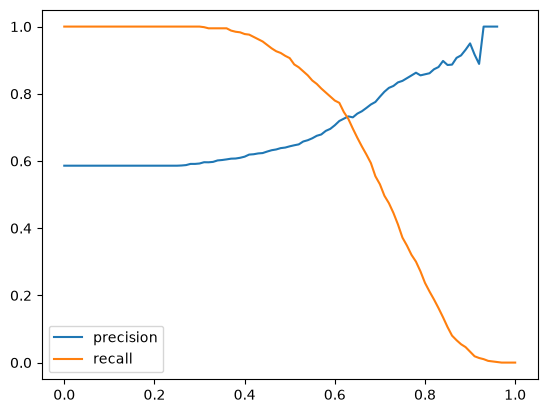

In [49]:
plt.plot(df_scores.thresholds, df_scores['p'], label='precision')
plt.plot(df_scores.thresholds, df_scores['r'], label='recall')
plt.legend() #Add the legend

In [69]:
df_scores['difference'] = abs(df_scores.p - df_scores.r)

In [74]:
df_scores.loc[df_scores['difference'].idxmin()]

thresholds      0.630000
tp            425.000000
fp            155.000000
fn            161.000000
tn            259.000000
p               0.732759
r               0.725256
difference      0.007503
Name: 63, dtype: float64

## Q4. F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the `F1` score - a metrics that takes into account both

This is the formula for computing `F1`:
 $$ F_1 = 2 \cdot \frac{p \cdot r}{p + r} $$

Where 
_p_ is precision and _r_ is recall.

Let's compute `F1` for all thresholds from $0.0$ to $1.0$ with increment $0.01$

At which threshold `F1` is maximal?

In [75]:
df_scores['f1'] = 2*((df_scores.p * df_scores.r)/(df_scores.p + df_scores.r))

In [77]:
df_scores.loc[df_scores['f1'].idxmax()]

thresholds      0.410000
tp            572.000000
fp            352.000000
fn             14.000000
tn             62.000000
p               0.619048
r               0.976109
difference      0.357062
f1              0.757616
Name: 41, dtype: float64

## Q5. 5-Fold CV

Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```
- Iterate over different folds of `df_full_train`
- Split the data into train and validation
- Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
- Use AUC to evaluate the model on validation
  
How large is standard deviation of the scores across different folds?

In [81]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    train_dicts = df_train[categorical + numerical].to_dict(orient='records')
    val_dicts = df_val[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)

print('AUC scores:', scores)

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]


In [82]:
print('Standard deviation:', np.std(scores))

Standard deviation: 0.006853233151022138


In [83]:
print(round(np.std(scores), 3))

0.007


## Q6. Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter `C`

- Iterate over the following `C` values: `[0.000001, 0.001, 1]`
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
  
Which `C` leads to the best mean ROC AUC?

In [89]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        train_dicts = df_train[categorical + numerical].to_dict(orient='records')
        val_dicts = df_val[categorical + numerical].to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc)

    print(f'C={C}: mean AUC={np.mean(scores):.12f},'f'std={np.std(scores):.12f}')

C=1e-06: mean AUC=0.731726971097,std=0.006853233151
C=0.001: mean AUC=0.731726971097,std=0.006853233151
C=1: mean AUC=0.731726971097,std=0.006853233151
